In [1]:
from prod_fs import ProD

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# Create random classification dataset
X, y = make_classification(
    n_samples=300, n_features=50, n_classes=5, n_informative=5,
    shuffle=False, random_state=124
)

In [2]:
# Initialize ProD object
prodRanker = ProD(k=2)

# Carry out feature selection
prodRanker.fit(X, y)

# Get feature rankings
feature_ranks = prodRanker.get_topnFeatures(50)

print(feature_ranks)
print(type(feature_ranks))

Constructing and evaluating the KDEs per class for every feature ... 
 - Kernels constructed!
Computing intersection areas ...
 - averaging_method: 'mean'
[1, 6, 4, 5, 0, 3, 2, 32, 43, 9, 13, 31, 48, 33, 20, 18, 10, 29, 44, 16, 11, 49, 17, 45, 12, 36, 46, 42, 37, 39, 38, 8, 40, 22, 27, 23, 41, 26, 30, 47, 35, 28, 15, 14, 25, 34, 24, 21, 19, 7]
<class 'list'>


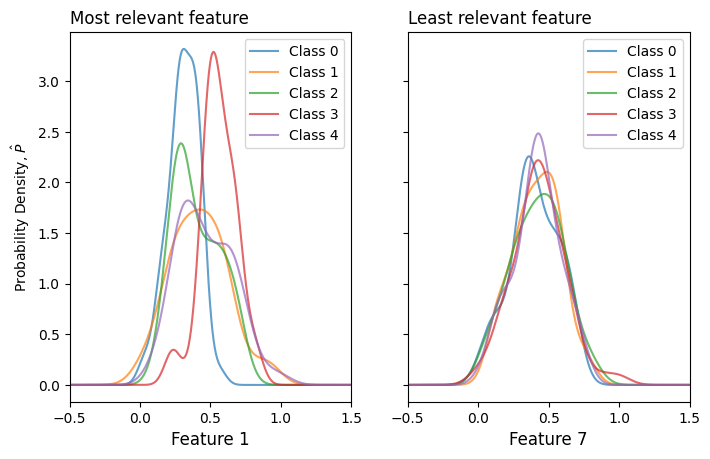

In [3]:
# Visualize the top feature's ability to segregate PDEs
fig, axs = plt.subplots(1, 2, figsize=(8.0, 4.8), sharey=True)

# Top ranked feature
prodRanker.plot_overlapAreas(feature_ranks[0], legend="class", _ax=axs[0], intersection_area=False)
axs[0].set_title("Most relevant feature", loc="left")

# Last ranked feature
prodRanker.plot_overlapAreas(feature_ranks[-1], legend="class", _ax=axs[1], intersection_area=False)
axs[1].set_title("Least relevant feature", loc="left")

axs[0].set_ylabel(r"Probability Density, $\hat{P}$")
for i in range(2):
    axs[i].set_xlim(-0.5, 1.5)
    axs[i].set_xticks(np.arange(-0.5, 2.0, 0.5))

fig.savefig("example_plot.svg", format="svg")

Averaging scheme: mean
Computing pairwise intersection areas ...


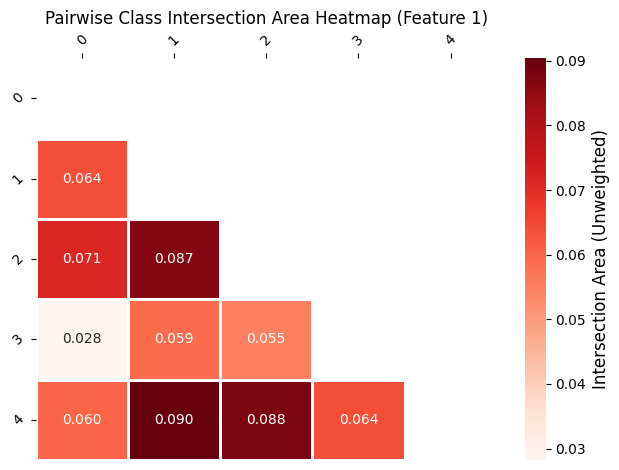

In [4]:
# Plot a heat map to investigate the pairwise class intersection areas
fig, ax = plt.subplots(1, 1)
prodRanker.plot_classPairHeatmaps(feature_ranks[0], _ax=ax)

fig.savefig("example_heatmap.svg", format="svg")